# DSCI 552 — Homework 7
**Name:** Anita Hovsepian

**Repository:** https://github.com/anitahov/Hovsepian_Anita_HW7.git

**USC ID:** 6881664760



## 1. Multi-class and Multi-label Classification Using Support Vector Machines

### Imports and data preparation

In [1]:
import os, warnings
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, hamming_loss, classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.multioutput import ClassifierChain
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import mode
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
# Repository specified for this assignment (primary data source).
# Clone the repository and locate Frogs_MFCCs.csv anywhere in its tree.
from pathlib import Path
import subprocess
REPOSITORY = 'https://github.com/anitahov/Hovsepian_Anita_HW7.git'
REPO_DIR = Path('Hovsepian_Anita_HW7')
if not REPO_DIR.exists():
    attempt = subprocess.run(['git', 'clone', '--depth', '1', REPOSITORY, str(REPO_DIR)],
                             capture_output=True, text=True)
    if attempt.returncode != 0:
        print('Repository clone unavailable:', attempt.stderr.strip()[:250])
repo_csv = sorted(REPO_DIR.rglob('Frogs_MFCCs.csv')) if REPO_DIR.exists() else []
if repo_csv:
    DATA_PATH = str(repo_csv[0])
    print('Using dataset from GitHub repository:', DATA_PATH)
else:
    # Uploaded dataset is a fallback only when the repository cannot supply the CSV.
    local_csv = next((p for p in ['Frogs_MFCCs.csv', '/mnt/data/Frogs_MFCCs.csv']
                      if os.path.exists(p)), None)
    if local_csv is None:
        raise FileNotFoundError('Frogs_MFCCs.csv was not found in the repository or locally.')
    DATA_PATH = local_csv
    print('Repository CSV unavailable; using supplied local dataset:', DATA_PATH)
df=pd.read_csv(DATA_PATH)
features=[c for c in df.columns if c.startswith('MFCCs')]
labels=['Family','Genus','Species']
X=df[features]; Y=df[labels]
print('Dataset:',df.shape,'MFCC features:',len(features))
print('Classes:',Y.nunique().to_dict())
display(Y.apply(lambda c:c.value_counts()).fillna(0).astype(int))

Using dataset from GitHub repository: Hovsepian_Anita_HW7/Frogs_MFCCs.csv
Dataset: (7195, 26) MFCC features: 22
Classes: {'Family': 4, 'Genus': 8, 'Species': 10}


,Family,Genus,Species
Adenomera,0,4150,0
AdenomeraAndre,0,0,672
AdenomeraHylaedactylus,0,0,3478
Ameerega,0,542,0
Ameeregatrivittata,0,0,542
Bufonidae,68,0,0
Dendrobatidae,542,0,0
Dendropsophus,0,310,0
HylaMinuta,0,0,310
Hylidae,2165,0,0


### 1(a) Random 70/30 train-test split
`RecordID` is an identifier, not a predictor. We use the same split for all three target labels.

In [2]:
X_train,X_test,y_train,y_test=train_test_split(X,Y,train_size=0.7,random_state=SEED,shuffle=True)
print('Training:',X_train.shape,'Test:',X_test.shape)

Training: (5036, 22) Test: (2159, 22)


### 1(b)(i) Evaluation definitions
For each observation, the predicted label triplet is compared with the three true labels. **Exact match (subset accuracy)** is the fraction of observations for which *all three* labels are correct. **Hamming loss** is the fraction of the total 3 × n label positions that are incorrect. **Hamming score**, defined here as `1 − Hamming loss`, is the fraction of label positions correctly predicted (micro label-wise accuracy). **Hamming distance per observation** is the number of mismatches among its three labels; the mean distance is `3 × Hamming loss`. These definitions are explicit because some sources use “Hamming score” to mean sample-wise Jaccard similarity for binary indicator labels, which is a different quantity.

References: scikit-learn documentation for `accuracy_score` and `hamming_loss`; Sorower, *A Literature Survey on Algorithms for Multi-label Learning*.

In [3]:
def multilabel_metrics(actual,predicted):
    a=np.asarray(actual); p=np.asarray(predicted)
    wrong=(a!=p)
    return {'Exact match':np.mean(~wrong.any(axis=1)),
            'Hamming distance':wrong.sum(axis=1).mean(),
            'Hamming score':1-wrong.mean(),
            'Hamming loss':wrong.mean()}
results={}
def fit_three(estimator, param_grid, name):
    predictions=pd.DataFrame(index=y_test.index)
    params={}; cv_scores={}
    for label in labels:
        cv=StratifiedKFold(n_splits=10,shuffle=True,random_state=SEED)
        search=GridSearchCV(estimator,param_grid,cv=cv,scoring='accuracy',n_jobs=1,refit=True)
        search.fit(X_train,y_train[label])
        predictions[label]=search.predict(X_test)
        params[label]=search.best_params_; cv_scores[label]=search.best_score_
        print(f'{name} | {label}: CV accuracy={search.best_score_:.4f}, test accuracy={accuracy_score(y_test[label],predictions[label]):.4f}, parameters={search.best_params_}')
    results[name]=multilabel_metrics(y_test,predictions)
    display(pd.DataFrame([results[name]],index=[name]).round(4))
    return predictions,params,cv_scores

### 1(b)(ii) Gaussian (RBF) SVM, one-vs-rest, 10-fold CV
Each target is fitted separately. `SVC` uses one-vs-one internally for multiclass; `OneVsRestClassifier(SVC(...))` explicitly implements the required one-vs-all scheme. The RBF width is controlled by `gamma` (γ = 1/(2σ²)). Standardization is learned on training folds only.

In [4]:
from sklearn.multiclass import OneVsRestClassifier
rbf_pipeline=Pipeline([('scale',StandardScaler()),('svm',OneVsRestClassifier(SVC(kernel='rbf')))])
rbf_grid={'svm__estimator__C':[0.1,1,10], 'svm__estimator__gamma':[0.01,0.1,1]}
rbf_pred,rbf_params,rbf_cv=fit_three(rbf_pipeline,rbf_grid,'RBF SVM')

RBF SVM | Family: CV accuracy=0.9905, test accuracy=0.9935, parameters={'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
RBF SVM | Genus: CV accuracy=0.9891, test accuracy=0.9884, parameters={'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}
RBF SVM | Species: CV accuracy=0.9889, test accuracy=0.9880, parameters={'svm__estimator__C': 10, 'svm__estimator__gamma': 0.1}


,Exact match,Hamming distance,Hamming score,Hamming loss
RBF SVM,0.9866,0.0301,0.99,0.01


### 1(b)(iii) L1-penalized linear SVM, 10-fold CV
The standard convention for L1 regularization is a linear kernel. `dual=False` is required for `LinearSVC(penalty="l1")`.

In [5]:
l1_pipeline=Pipeline([('scale',StandardScaler()),('svm',LinearSVC(penalty='l1',dual=False,max_iter=15000,random_state=SEED))])
l1_grid={'svm__C':[0.01,0.1,1,10]}
l1_pred,l1_params,l1_cv=fit_three(l1_pipeline,l1_grid,'L1 Linear SVM')

L1 Linear SVM | Family: CV accuracy=0.9412, test accuracy=0.9282, parameters={'svm__C': 10}
L1 Linear SVM | Genus: CV accuracy=0.9516, test accuracy=0.9416, parameters={'svm__C': 10}
L1 Linear SVM | Species: CV accuracy=0.9607, test accuracy=0.9592, parameters={'svm__C': 10}


,Exact match,Hamming distance,Hamming score,Hamming loss
L1 Linear SVM,0.9125,0.1709,0.943,0.057


### 1(b)(iv) L1 SVM with SMOTE inside CV folds
SMOTE is applied **only to each training fold** through an imbalanced-learn pipeline, preventing leakage into validation/test observations. The model is trained independently for each target.

In [7]:

smote_pipeline = ImbPipeline([
    ('scale', StandardScaler()),
    ('smote', SMOTE(random_state=SEED, k_neighbors=3)),
    ('svm', LinearSVC(
        penalty='l1',
        dual=False,
        max_iter=3000,
        tol=1e-3,
        random_state=SEED
    ))
])

smote_grid = {'svm__C': [0.01, 0.1, 1, 10]}

smote_pred, smote_params, smote_cv = fit_three(
    smote_pipeline,
    smote_grid,
    'L1 SVM + SMOTE'
)

comparison = pd.DataFrame(results).T.sort_values(
    'Hamming loss'
)

print('Test-set comparison:')
display(comparison.round(4))

best = comparison.index[0]
print('Best model:', best)


L1 SVM + SMOTE | Family: CV accuracy=0.9204, test accuracy=0.9064, parameters={'svm__C': 1}
L1 SVM + SMOTE | Genus: CV accuracy=0.9118, test accuracy=0.9013, parameters={'svm__C': 10}
L1 SVM + SMOTE | Species: CV accuracy=0.9579, test accuracy=0.9588, parameters={'svm__C': 1}


,Exact match,Hamming distance,Hamming score,Hamming loss
L1 SVM + SMOTE,0.8509,0.2334,0.9222,0.0778


Test-set comparison:


,Exact match,Hamming distance,Hamming score,Hamming loss
RBF SVM,0.9866,0.0301,0.9900,0.0100
L1 Linear SVM,0.9125,0.1709,0.9430,0.0570
L1 SVM + SMOTE,0.8509,0.2334,0.9222,0.0778


Best model: RBF SVM


### 1(b)(v) Extra practice — classifier chains
A classifier chain allows predictions of earlier labels to become features for later ones. This is an additional experiment, not part of the required comparison.

In [9]:
from sklearn.preprocessing import LabelEncoder
from sklearn.multioutput import ClassifierChain
import inspect

encoders = {
    label: LabelEncoder().fit(Y[label])
    for label in labels
}

y_train_int = np.column_stack([
    encoders[label].transform(y_train[label])
    for label in labels
])

base_model = Pipeline([
    ('scale', StandardScaler()),
    ('svm', LinearSVC(
        C=1,
        dual=False,
        max_iter=3000,
        tol=1e-3,
        random_state=SEED
    ))
])

# Compatible with different scikit-learn versions
parameter_name = (
    'estimator'
    if 'estimator' in inspect.signature(ClassifierChain).parameters
    else 'base_estimator'
)

chain = ClassifierChain(
    **{parameter_name: base_model},
    order=[0, 1, 2],
    cv=None,
    random_state=SEED
)

chain.fit(X_train, y_train_int)

chain_encoded = chain.predict(X_test).astype(int)

chain_pred = np.column_stack([
    encoders[label].inverse_transform(chain_encoded[:, i])
    for i, label in enumerate(labels)
])

results['Classifier chain (extra)'] = multilabel_metrics(
    y_test,
    chain_pred
)

display(
    pd.DataFrame(
        [results['Classifier chain (extra)']],
        index=['Classifier chain']
    ).round(4)
)


,Exact match,Hamming distance,Hamming score,Hamming loss
Classifier chain,0.9171,0.2209,0.9264,0.0736


### 1(b)(vi) Extra practice — per-label confusion matrices, precision and recall
For each multiclass target, a confusion matrix is displayed and macro precision, recall, and F1 are calculated. ROC/AUC for multiclass problems requires a one-vs-rest binarization and per-class decision scores; we use the RBF SVM predictions for the confusion-matrix summary and report macro OvR AUC from refitted best estimators.


 Family


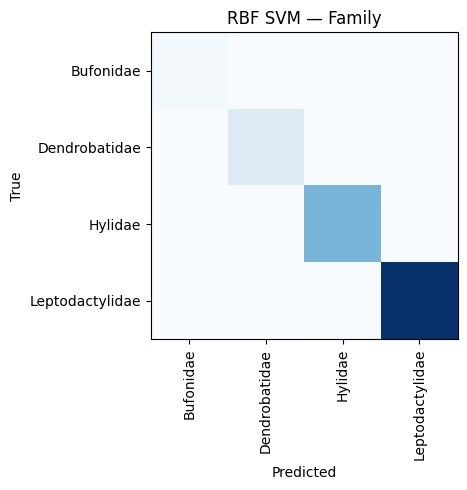

Macro precision=0.9947; recall=0.9700; F1=0.9815
Macro OvR AUC: 0.9995

 Genus


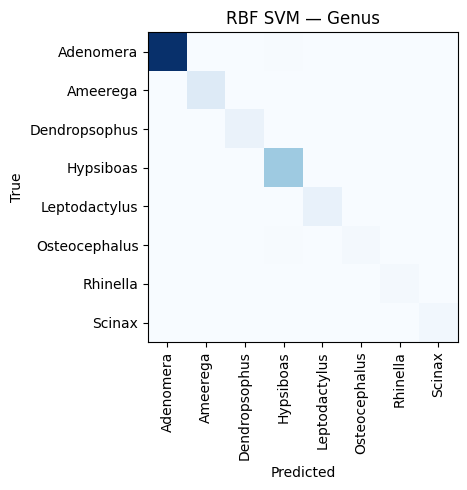

Macro precision=0.9846; recall=0.9514; F1=0.9671
Macro OvR AUC: 0.9982

 Species


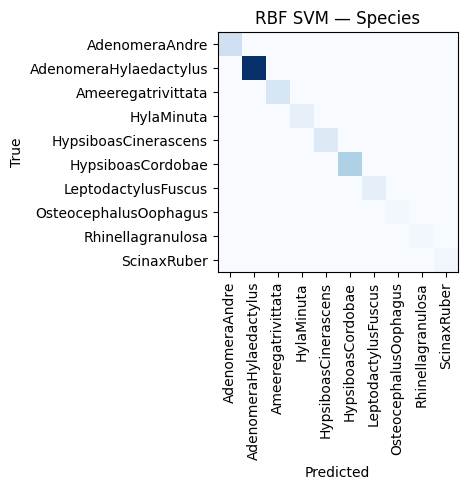

Macro precision=0.9780; recall=0.9606; F1=0.9689
Macro OvR AUC: 0.9982


In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.base import clone
for label in labels:
    print('\n',label)
    classes=np.unique(y_train[label]); cm=confusion_matrix(y_test[label],rbf_pred[label],labels=classes)
    fig,ax=plt.subplots(figsize=(6,5)); ax.imshow(cm,cmap='Blues'); ax.set_xticks(range(len(classes)),classes,rotation=90);ax.set_yticks(range(len(classes)),classes);ax.set_title(f'RBF SVM — {label}');ax.set_xlabel('Predicted');ax.set_ylabel('True');plt.tight_layout();plt.show()
    p,r,f,_=precision_recall_fscore_support(y_test[label],rbf_pred[label],average='macro',zero_division=0)
    print(f'Macro precision={p:.4f}; recall={r:.4f}; F1={f:.4f}')
    model=clone(rbf_pipeline).set_params(**rbf_params[label]).fit(X_train,y_train[label])
    # OvR SVC decision scores are not calibrated probabilities; use sigmoid-style per-class scores via predict_proba.
    prob_model=clone(rbf_pipeline).set_params(**rbf_params[label],svm__estimator__probability=True).fit(X_train,y_train[label])
    # OneVsRestClassifier multiclass predict_proba columns correspond to sorted classes.
    scores=prob_model.predict_proba(X_test)
    try: print('Macro OvR AUC:',round(roc_auc_score(y_test[label],scores,multi_class='ovr',average='macro',labels=prob_model.named_steps['svm'].classes_),4))
    except ValueError as e: print('AUC unavailable:',e)

## 2. K-Means Clustering: 50 Monte Carlo repetitions
Use **all** observations, with no supervised train/test split. For each repetition, choose K automatically using the **Calinski–Harabasz (CH)** index. K=1 is not valid for CH, so candidate K values are 2–50 (K=1 cannot be scored by this criterion). For tractability, a random 500-observation subsample is used **only to select K**; the final K-means is fitted to **all 7,195 records**. We evaluate candidate K values in the full 2–50 range, using `MiniBatchKMeans` for efficient selection; final labels come from standard KMeans. Random seeds change across the 50 repetitions.

For each cluster, assign the modal true family, genus, and species **independently**, as requested. These modal labels are used only to assess the clustering, not to fit it. The resulting triplet need not correspond to a biologically valid combination.

In [11]:
from sklearn.cluster import MiniBatchKMeans
X_all=X.to_numpy(dtype=float)
y_all=Y.to_numpy()
def majority_triplets(cluster_ids,truth):
    pred=np.empty_like(truth,dtype=object)
    majority={}
    for cluster in np.unique(cluster_ids):
        ix=np.flatnonzero(cluster_ids==cluster)
        triplet=[]
        for j in range(truth.shape[1]):
            values,counts=np.unique(truth[ix,j],return_counts=True)
            triplet.append(values[np.argmax(counts)])
        majority[int(cluster)]=tuple(triplet)
        pred[ix,:]=triplet
    return pred,majority
k_candidates=list(range(2,51))
records=[]; all_majorities=[]
for repeat in range(50):
    rng=np.random.default_rng(SEED+repeat)
    subsample=rng.choice(len(X_all),size=500,replace=False)
    xs=X_all[subsample]
    ch=[]
    for k in k_candidates:
        km=MiniBatchKMeans(n_clusters=k,random_state=SEED+repeat,n_init=1,batch_size=256,max_iter=35)
        ids=km.fit_predict(xs)
        ch.append(calinski_harabasz_score(xs,ids) if len(np.unique(ids))>1 else -np.inf)
    best_k=k_candidates[int(np.argmax(ch))]
    final=KMeans(n_clusters=best_k,random_state=SEED+repeat,n_init=2,max_iter=100)
    clusters=final.fit_predict(X_all)
    predicted,majorities=majority_triplets(clusters,y_all)
    row={'Run':repeat+1,'K':best_k,**multilabel_metrics(y_all,predicted)}
    records.append(row);all_majorities.append(majorities)
    if (repeat+1)%10==0: print(f'Completed {repeat+1}/50 Monte Carlo runs')
mc=pd.DataFrame(records)
display(mc.head(10).round(4))
print('Mean and standard deviation across 50 runs:')
display(mc[['K','Hamming distance','Hamming score','Hamming loss','Exact match']].agg(['mean','std']).round(4))

Completed 10/50 Monte Carlo runs
Completed 20/50 Monte Carlo runs
Completed 30/50 Monte Carlo runs
Completed 40/50 Monte Carlo runs
Completed 50/50 Monte Carlo runs


,Run,K,Exact match,Hamming distance,Hamming score,Hamming loss
0,1,3,0.6363,0.8905,0.7032,0.2968
1,2,2,0.6361,0.8956,0.7015,0.2985
2,3,2,0.6361,0.8956,0.7015,0.2985
3,4,2,0.6361,0.8956,0.7015,0.2985
4,5,2,0.6361,0.8956,0.7015,0.2985
5,6,3,0.7070,0.7155,0.7615,0.2385
6,7,2,0.6361,0.8956,0.7015,0.2985
7,8,2,0.6361,0.8956,0.7015,0.2985
8,9,2,0.6361,0.8956,0.7015,0.2985
9,10,2,0.6361,0.8956,0.7015,0.2985


Mean and standard deviation across 50 runs:


,K,Hamming distance,Hamming score,Hamming loss,Exact match
mean,2.1600,0.8880,0.7040,0.2960,0.639
std,0.4219,0.0356,0.0119,0.0119,0.014


### 2(b) Majority label triplets for a representative run
The following table reports the cluster-wise modal labels from run 1.

,Cluster,Family,Genus,Species
0,0,Hylidae,Hypsiboas,HypsiboasCordobae
1,1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
2,2,Hylidae,Hypsiboas,HypsiboasCordobae


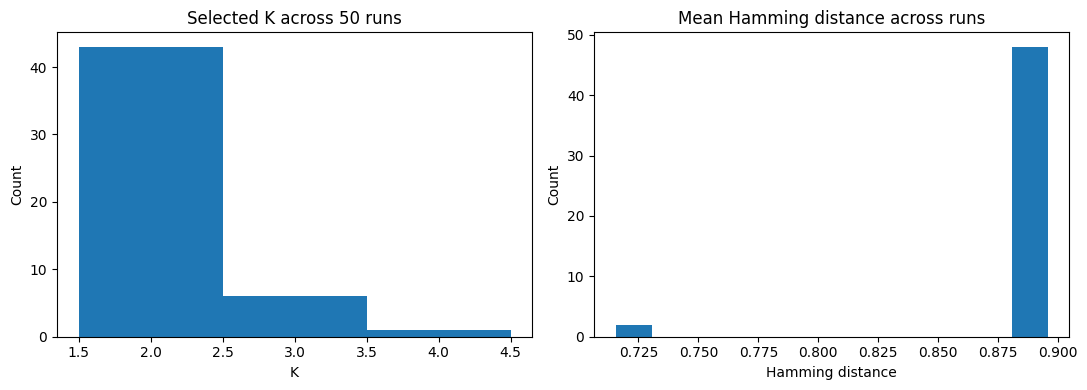

In [12]:
majority_table=pd.DataFrame([{'Cluster':k,'Family':v[0],'Genus':v[1],'Species':v[2]} for k,v in sorted(all_majorities[0].items())])
display(majority_table)
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].hist(mc['K'],bins=np.arange(mc.K.min()-0.5,mc.K.max()+1.5,1));axs[0].set_title('Selected K across 50 runs');axs[0].set_xlabel('K');axs[0].set_ylabel('Count')
axs[1].hist(mc['Hamming distance'],bins=12);axs[1].set_title('Mean Hamming distance across runs');axs[1].set_xlabel('Hamming distance');axs[1].set_ylabel('Count')
plt.tight_layout();plt.show()

### 2(c) Clustering evaluation and conclusion

In [13]:
print('Average Hamming distance:',mc['Hamming distance'].mean())
print('Standard deviation Hamming distance:',mc['Hamming distance'].std(ddof=1))
print('Average Hamming score:',mc['Hamming score'].mean())
print('Average Hamming loss:',mc['Hamming loss'].mean())
print('Since there are three labels, Hamming distance = 3 × Hamming loss in every run.')
print('The modal labels are assigned after clustering, so these scores measure cluster-label agreement rather than out-of-sample classification performance.')

Average Hamming distance: 0.8879638637943016
Standard deviation Hamming distance: 0.035590868660658255
Average Hamming score: 0.7040120454018993
Average Hamming loss: 0.29598795459810057
Since there are three labels, Hamming distance = 3 × Hamming loss in every run.
The modal labels are assigned after clustering, so these scores measure cluster-label agreement rather than out-of-sample classification performance.


## 3. ISLR (2nd edition) Exercise 12.6.2 — Hierarchical clustering
The exercise specifies four observations with pairwise dissimilarities d₁₂=0.30, d₁₃=0.40, d₁₄=0.70, d₂₃=0.50, d₂₄=0.80, d₃₄=0.45. Source: *An Introduction to Statistical Learning*, 2nd ed., §12.6, Exercise 2, https://www.statlearning.com/.

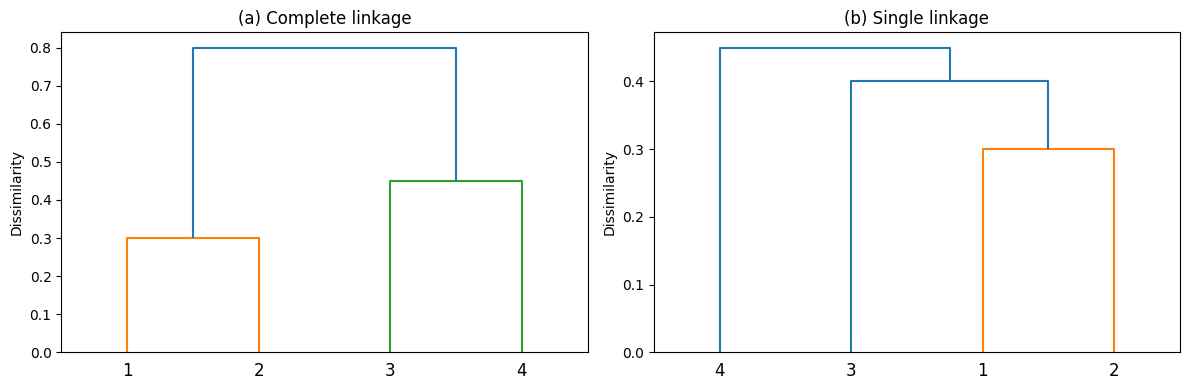

(a) Complete linkage merge heights: [0.3  0.45 0.8 ]
(b) Single linkage merge heights: [0.3  0.4  0.45]
(c) Complete two clusters: [[np.int64(1), np.int64(2)], [np.int64(3), np.int64(4)]]
(d) Single two clusters: [[np.int64(1), np.int64(2), np.int64(3)], [np.int64(4)]]


In [14]:
D=np.array([[0,.30,.40,.70],[.30,0,.50,.80],[.40,.50,0,.45],[.70,.80,.45,0]])
condensed=squareform(D)
Z_complete=linkage(condensed,method='complete')
Z_single=linkage(condensed,method='single')
fig,axs=plt.subplots(1,2,figsize=(12,4))
dendrogram(Z_complete,labels=['1','2','3','4'],ax=axs[0]);axs[0].set_title('(a) Complete linkage');axs[0].set_ylabel('Dissimilarity')
dendrogram(Z_single,labels=['1','2','3','4'],ax=axs[1]);axs[1].set_title('(b) Single linkage');axs[1].set_ylabel('Dissimilarity')
plt.tight_layout();plt.show()
print('(a) Complete linkage merge heights:',Z_complete[:,2])
print('(b) Single linkage merge heights:',Z_single[:,2])
for name,Z in [('(c) Complete',Z_complete),('(d) Single',Z_single)]:
    groups=fcluster(Z,t=2,criterion='maxclust')
    print(name,'two clusters:',[list(np.flatnonzero(groups==i)+1) for i in np.unique(groups)])

**(a)** Complete linkage first merges {1,2} at 0.30, then {3,4} at 0.45, then the two groups at 0.80 (their maximum cross-group dissimilarity). **(b)** Single linkage first merges {1,2} at 0.30, then observation 3 at 0.40, then observation 4 at 0.45. **(c)** Complete linkage with two clusters: {1,2} and {3,4}. **(d)** Single linkage with two clusters: {1,2,3} and {4}. **(e)** Reversing the leaf order of either child subtree yields an equivalent dendrogram; the next plot reverses the entire complete-linkage leaf order without changing its merge heights.

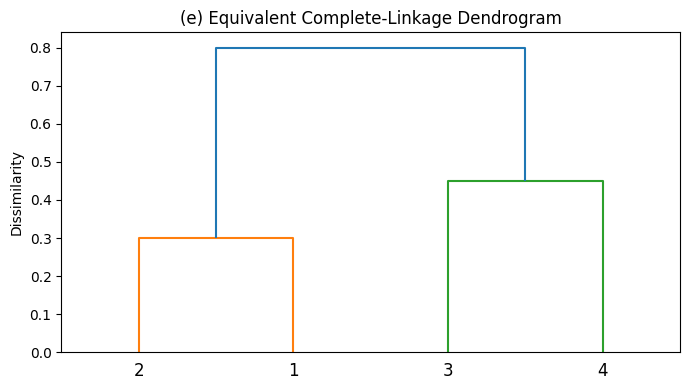

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))

# Swap the positions of leaves 1 and 2
Z_equiv = Z_complete.copy()
Z_equiv[0, 0], Z_equiv[0, 1] = (
    Z_equiv[0, 1], Z_equiv[0, 0]
)

dendrogram(
    Z_equiv,
    labels=['1', '2', '3', '4'],
    ax=ax
)

ax.set_title('(e) Equivalent Complete-Linkage Dendrogram')
ax.set_ylabel('Dissimilarity')
plt.tight_layout()
plt.show()
